<a href="https://colab.research.google.com/github/mrbedoya/ml-2026/blob/main/18_EvaluacionEntreModelosRegresion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluación entre diferentes modelos de regresión

## 1. Librerias y configuraciones previas


In [1]:
# Tratamiento de datos
# ==============================================================================
import pandas as pd
import numpy as np


# Almacenar en caché los resultados de funciones en el disco
# ==============================================================================
import joblib


# Gestion de librerias
# ==============================================================================
from importlib import reload

# Matemáticas y estadísticas
# ==============================================================================
import math

# Preprocesado y modelado
# ==============================================================================

# Preparación de datos
from sklearn.neighbors import LocalOutlierFactor

# Separar los datos entrenamiento y prueba
from sklearn.model_selection import train_test_split

# Escalar Variables
from sklearn.preprocessing import MinMaxScaler

# Evaluación del modelo
from sklearn import metrics

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns

# Interuactuar con os y solicitudes desde HTTP
# ==============================================================================
import os
import sys
import requests

# Configuración warnings
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Parametros globales
# ==============================================================================

# Construimos la URL de la API de GitHub para el directorio de modelos
# El formato es: https://api.github.com/repos/{owner}/{repo}/contents/{path}
api_url = "https://api.github.com/repos/mrbedoya/ml-2026/contents/modelos/regresion"

# URL base de GitHub para el repositorio
GITHUB_BASE_URL = 'https://raw.githubusercontent.com/mrbedoya/ml-2026/main/'

# Nombres de los archivos requeridos
DATASET_FILE_NAME_PRUE = '01_carDetailsV4_Prue.csv'
DATASET_FILE_NAME_PREP = '01_carDetailsV4_Prep.csv'
UTILS_FILE_NAME = 'funciones.py'
SCALER_FILE_NAME = 'minmaxFull_carDetailsV4.pkl'

# Nombres de los directorios para utilidades, datasets y modelos
DATASETS_PATH = 'datasets/'
UTILS_PATH = 'utils/'
MODELS_PATH = 'modelos/'
MODELS_REGRESION_PATH = os.path.join(MODELS_PATH, 'regresion')
MODELS_SCALER_PATH = os.path.join(MODELS_PATH, 'scaler')

# URL completa del dataset y utils en GitHub
github_dataset_url_prue = os.path.join(GITHUB_BASE_URL, DATASETS_PATH, DATASET_FILE_NAME_PRUE)
github_dataset_url_prep = os.path.join(GITHUB_BASE_URL, DATASETS_PATH, DATASET_FILE_NAME_PREP)
github_utils_url = os.path.join(GITHUB_BASE_URL, UTILS_PATH, UTILS_FILE_NAME)
github_scaler_url = os.path.join(GITHUB_BASE_URL, MODELS_SCALER_PATH, SCALER_FILE_NAME)

# Rutas locales completas de datasets y utils
local_dataset_path_prue = os.path.join(DATASETS_PATH, DATASET_FILE_NAME_PRUE)
local_dataset_path_prep = os.path.join(DATASETS_PATH, DATASET_FILE_NAME_PREP)
local_utils_path = os.path.join(UTILS_PATH, UTILS_FILE_NAME)
local_scaler_path = os.path.join(MODELS_SCALER_PATH, SCALER_FILE_NAME)

In [3]:
## Cargar datos desde Google Drive
## ==============================================================================

#from google.colab import drive

## Montar Google Drive
#drive.mount('/gdrive')

## Establece el directorio de trabajo dentro de directorio espefíficado en Google Drive
#os.chdir("/gdrive/MyDrive/01_Academia/02_Cursos/20260401_ApredinzajeAutomáticoI_UdeA/")

## Listar archivos de directorio
##!ls

In [4]:
# Funcion local para la carga de archivos
# ==============================================================================

def download_file(url, path, description):
    '''
    Descarga un archivo desde una URL y lo guarda localmente.

    Args:
        url (str): URL del archivo
        path (str): Ruta local de destino
        description (str): Descripción del archivo
    Returns:
        None
    '''
    print(f"Descargando {description} desde: {url}")

    # Realiza una solicitud HTTP GET a la URL proporcionada
    response = requests.get(url)

    # Lanza una excepción si la descarga falla (código de estado HTTP no 200)
    response.raise_for_status()

    # Abre el archivo local en modo de escritura binaria ('wb')
    with open(path, 'wb') as f:
        # Escribe el contenido binario de la respuesta HTTP en el archivo local
        f.write(response.content)

    # Imprime un mensaje confirmando que la descarga fue exitosa y la ruta de guardado
    print(f"{description} descargado exitosamente a: {path}")

In [5]:
# Configuración entorno Colab
# ==============================================================================

# Creación de directorios locales
os.makedirs(DATASETS_PATH, exist_ok=True)
os.makedirs(UTILS_PATH, exist_ok=True)
os.makedirs(MODELS_PATH, exist_ok=True)

# Crear subdirectorios específicos para modelos y escalados
os.makedirs(MODELS_REGRESION_PATH, exist_ok=True)
os.makedirs(MODELS_SCALER_PATH, exist_ok=True)

# Descarga de archivos
download_file(github_dataset_url_prue, local_dataset_path_prue, "dataset")
download_file(github_dataset_url_prep, local_dataset_path_prep, "dataset")
download_file(github_utils_url, local_utils_path, "funciones")
download_file(github_scaler_url,local_scaler_path, "scaler")

Descargando dataset desde: https://raw.githubusercontent.com/mrbedoya/ml-2026/main/datasets/01_carDetailsV4_Prue.csv
dataset descargado exitosamente a: datasets/01_carDetailsV4_Prue.csv
Descargando dataset desde: https://raw.githubusercontent.com/mrbedoya/ml-2026/main/datasets/01_carDetailsV4_Prep.csv
dataset descargado exitosamente a: datasets/01_carDetailsV4_Prep.csv
Descargando funciones desde: https://raw.githubusercontent.com/mrbedoya/ml-2026/main/utils/funciones.py
funciones descargado exitosamente a: utils/funciones.py
Descargando scaler desde: https://raw.githubusercontent.com/mrbedoya/ml-2026/main/modelos/scaler/minmaxFull_carDetailsV4.pkl
scaler descargado exitosamente a: modelos/scaler/minmaxFull_carDetailsV4.pkl


In [6]:
# Obtener la lista de archivos desde la API de GitHub
# ==============================================================================

print(f"Consultando lista de modelos en: {api_url}")
response = requests.get(api_url)
response.raise_for_status()

# Filtrar solo archivos .pkl
repo_contents = response.json()
model_file_names = [file['name'] for file in repo_contents if file['name'].endswith('.pkl')]

print(f"Modelos encontrados: {model_file_names}")

# Descargar cada modelo encontrado
for model_name in model_file_names:
    github_model_url = os.path.join(GITHUB_BASE_URL, MODELS_REGRESION_PATH, model_name)
    local_model_path = os.path.join(MODELS_REGRESION_PATH, model_name)
    download_file(github_model_url, local_model_path, f"modelo {model_name}")

Consultando lista de modelos en: https://api.github.com/repos/mrbedoya/ml-2026/contents/modelos/regresion
Modelos encontrados: ['ABoostR_CV.pkl', 'DTreeR_CV.pkl', 'DTreeR_CV_ccp.pkl', 'GBoostR_CV.pkl', 'RForest_CV.pkl', 'SVR_CV_poly.pkl']
Descargando modelo ABoostR_CV.pkl desde: https://raw.githubusercontent.com/mrbedoya/ml-2026/main/modelos/regresion/ABoostR_CV.pkl
modelo ABoostR_CV.pkl descargado exitosamente a: modelos/regresion/ABoostR_CV.pkl
Descargando modelo DTreeR_CV.pkl desde: https://raw.githubusercontent.com/mrbedoya/ml-2026/main/modelos/regresion/DTreeR_CV.pkl
modelo DTreeR_CV.pkl descargado exitosamente a: modelos/regresion/DTreeR_CV.pkl
Descargando modelo DTreeR_CV_ccp.pkl desde: https://raw.githubusercontent.com/mrbedoya/ml-2026/main/modelos/regresion/DTreeR_CV_ccp.pkl
modelo DTreeR_CV_ccp.pkl descargado exitosamente a: modelos/regresion/DTreeR_CV_ccp.pkl
Descargando modelo GBoostR_CV.pkl desde: https://raw.githubusercontent.com/mrbedoya/ml-2026/main/modelos/regresion/GB

## 2. Funciones

In [7]:
## Funciones externas
# ==============================================================================

## Añade la ruta definida en 'UTILS_PATH' al 'sys.path' para que Python pueda encontrar módulos
sys.path.append(UTILS_PATH)

## Importar Funciones externas
from funciones import multiple_plot

## 3. Carga del dataset

In [8]:
#Carga del dataset

dp=pd.read_csv(local_dataset_path_prue)
dp.shape

(206, 15)

In [9]:
dp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 206 entries, 0 to 205
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Price               206 non-null    float64
 1   Year                206 non-null    int64  
 2   Kilometer           206 non-null    int64  
 3   Engine              206 non-null    float64
 4   Length              206 non-null    float64
 5   Width               206 non-null    float64
 6   Height              206 non-null    float64
 7   Seating Capacity    206 non-null    float64
 8   Fuel Tank Capacity  206 non-null    float64
 9   Fuel Type           206 non-null    object 
 10  Transmission        206 non-null    object 
 11  Owner               206 non-null    object 
 12  Seller Type         206 non-null    object 
 13  Drivetrain          206 non-null    object 
 14  PriceRange          206 non-null    int64  
dtypes: float64(7), int64(3), object(5)
memory usage: 24.3+ KB

## 4. Visualización de datos

### Variables de entrada

In [10]:
#Lista de variables categóricas
catCols = dp.select_dtypes(include = ["object", 'category']).columns.tolist()

dp[catCols].head(2)

,Fuel Type,Transmission,Owner,Seller Type,Drivetrain
0,Diesel,Manual,Second,Individual,FWD
1,Petrol,Automatic,Second,Individual,FWD


In [11]:
#Lista de variables numéricas

numCols=dp.select_dtypes(include = ['float64','float64','int32','int64']).columns.tolist()

dp[numCols].head(2)

,Price,Year,Kilometer,Engine,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,PriceRange
0,5940.0,2017,38258,1248.0,3840.0,1735.0,1530.0,5.0,37.0,0
1,5100.0,2014,24000,1598.0,4386.0,1699.0,1466.0,5.0,55.0,1


In [12]:
## Visualización de frecuencia de instancias para variables categóricas
#multiple_plot(3, dp , catCols, None, 'countplot', 'Frecuencia de instancias para variables categóricas',30)

In [13]:
## Visualización de variables numéricas
#multiple_plot(1, dp , numCols, None, 'scatterplot', 'Relación entre las variables numéricas',30)

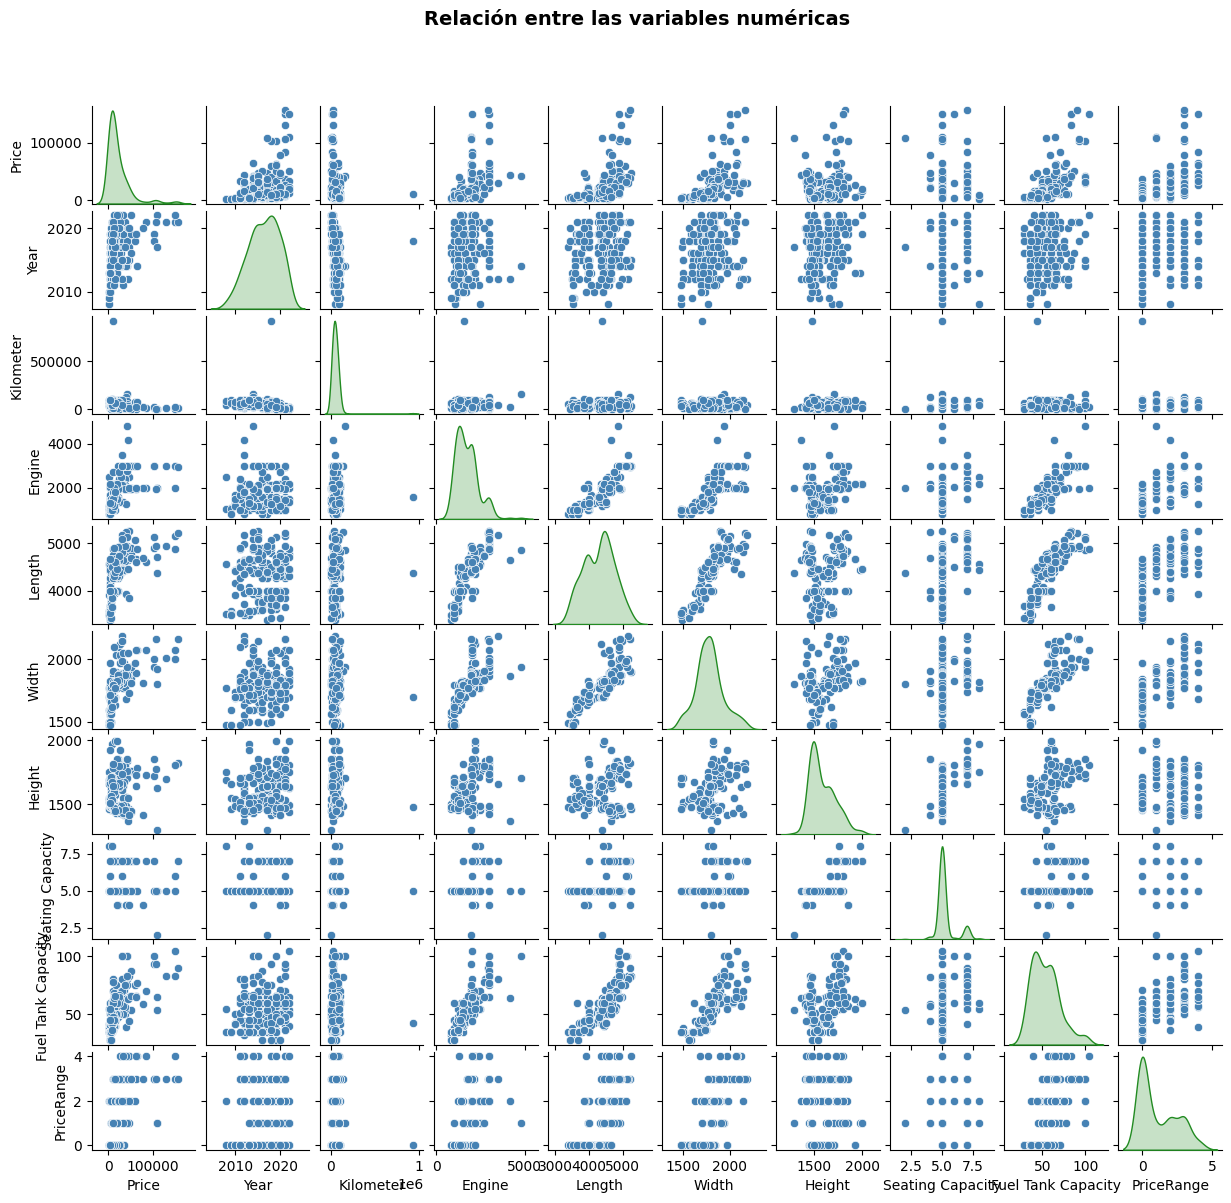

In [14]:
#Visualización de variables numéricas con respecto al precio
multiple_plot(1, dp , numCols, None, 'scatterplot', 'Relación entre las variables numéricas',30)

In [15]:
#Eliminar la variable de salida de la lista de variable numéricas
numCols.remove('Price')

### Variable de salida

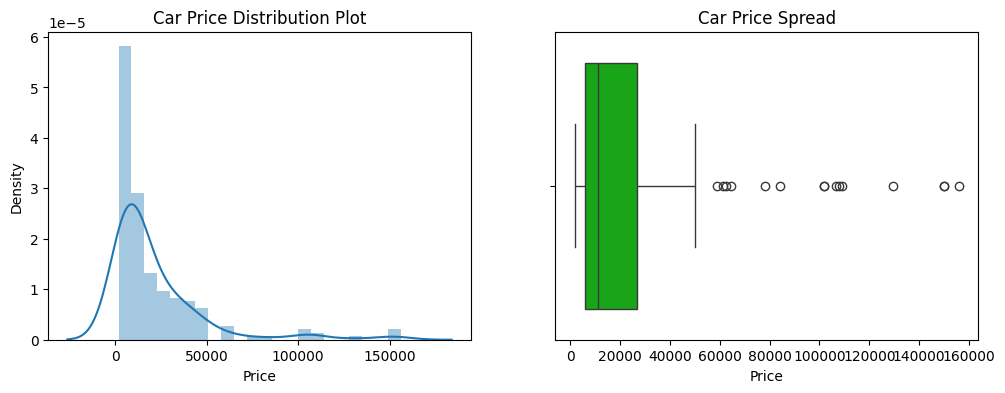

In [16]:
#Histográma y caja de bigotes del precio de los vehículos

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.title('Car Price Distribution Plot')
sns.distplot(dp.Price)

plt.subplot(1,2,2)
plt.title('Car Price Spread')
sns.boxplot(x=dp.Price, palette='nipy_spectral')

plt.show()

In [17]:
pd.set_option('display.float_format', lambda x: '%.0f' % x)

print(dp.Price.describe(percentiles = [0.25,0.50,0.75,0.85,0.90,0.95,0.975,1]))

count      206
mean     21488
std      27074
min       1680
25%       5820
50%      11220
75%      26850
85%      37500
90%      46800
95%      74625
97.5%   107850
100%    156000
max     156000
Name: Price, dtype: float64


## 5. Transformación de datos

### Creación de variables Dummies

In [18]:
# Aplicación de la función de usuario Dummies: one-hot encoding

dp =pd.get_dummies(dp, drop_first=1)

dp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 206 entries, 0 to 205
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Price                206 non-null    float64
 1   Year                 206 non-null    int64  
 2   Kilometer            206 non-null    int64  
 3   Engine               206 non-null    float64
 4   Length               206 non-null    float64
 5   Width                206 non-null    float64
 6   Height               206 non-null    float64
 7   Seating Capacity     206 non-null    float64
 8   Fuel Tank Capacity   206 non-null    float64
 9   PriceRange           206 non-null    int64  
 10  Fuel Type_Otro       206 non-null    bool   
 11  Fuel Type_Petrol     206 non-null    bool   
 12  Transmission_Manual  206 non-null    bool   
 13  Owner_Otro           206 non-null    bool   
 14  Owner_Second         206 non-null    bool   
 15  Seller Type_Otro     206 non-null    boo

### Columnas categóricas faltantes

In [19]:
#Carga del dataset

d=pd.read_csv(local_dataset_path_prep)
d.shape

(1436, 15)

In [20]:
# Aplicación de la función de usuario Dummies: one-hot encoding

d =pd.get_dummies(d, drop_first=1)

d.shape

(1436, 18)

In [21]:
# Obtener las columnas categóricas que están en el dataframe original pero no en el dataset de pruebas

missingCols = set(d.columns) - set(dp.columns)
missingCols

set()

In [22]:
# Agregar columnas con valores predeterminados 0
for col in missingCols:
    dp[col] = 0

In [23]:
#Se establece las variables de entrada 'X' y la variable de salida 'y'

Xp = dp.drop(columns ='Price')
yp = dp['Price']

In [24]:
#Escalar Variables númericas

pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Cargar el scaler
scaler = joblib.load(local_scaler_path)

# Se escalan los valores del dataset entrenamiento y prueba de las columnas numéricas
Xp[numCols] = scaler.transform(Xp[numCols])

Xp[numCols].head(2)

,Year,Kilometer,Engine,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,PriceRange
0,0.8529,0.2609,0.1176,0.2396,0.3672,0.3338,0.5000,0.1370,0.0000
1,0.7647,0.1621,0.2080,0.5337,0.3164,0.2421,0.5000,0.3836,0.2000


## 6. Creación del modelo

#### Creación y entrenamiento del modelo

In [25]:
Xp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 206 entries, 0 to 205
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year                 206 non-null    float64
 1   Kilometer            206 non-null    float64
 2   Engine               206 non-null    float64
 3   Length               206 non-null    float64
 4   Width                206 non-null    float64
 5   Height               206 non-null    float64
 6   Seating Capacity     206 non-null    float64
 7   Fuel Tank Capacity   206 non-null    float64
 8   PriceRange           206 non-null    float64
 9   Fuel Type_Otro       206 non-null    bool   
 10  Fuel Type_Petrol     206 non-null    bool   
 11  Transmission_Manual  206 non-null    bool   
 12  Owner_Otro           206 non-null    bool   
 13  Owner_Second         206 non-null    bool   
 14  Seller Type_Otro     206 non-null    bool   
 15  Drivetrain_FWD       206 non-null    boo

In [26]:
Xp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 206 entries, 0 to 205
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year                 206 non-null    float64
 1   Kilometer            206 non-null    float64
 2   Engine               206 non-null    float64
 3   Length               206 non-null    float64
 4   Width                206 non-null    float64
 5   Height               206 non-null    float64
 6   Seating Capacity     206 non-null    float64
 7   Fuel Tank Capacity   206 non-null    float64
 8   PriceRange           206 non-null    float64
 9   Fuel Type_Otro       206 non-null    bool   
 10  Fuel Type_Petrol     206 non-null    bool   
 11  Transmission_Manual  206 non-null    bool   
 12  Owner_Otro           206 non-null    bool   
 13  Owner_Second         206 non-null    bool   
 14  Seller Type_Otro     206 non-null    bool   
 15  Drivetrain_FWD       206 non-null    boo

In [30]:
# Inicializa una lista vacía para almacenar los modelos cargados.
modelos_cargados = []

# Crea un DataFrame vacío para almacenar resultados y métricas de los modelos.
dr = pd.DataFrame()

# Itera sobre los archivos en la ruta especificada (MODELS_REGRESION_PATH).
for archivo_modelo in os.listdir(MODELS_REGRESION_PATH):
    # Verifica si el archivo es un modelo con extensión '.pkl' (archivos serializados con joblib).
    if archivo_modelo.endswith('.pkl'):
        # Construye la ruta completa al archivo del modelo.
        ruta_completa = os.path.join(MODELS_REGRESION_PATH, archivo_modelo)

        # Carga el modelo utilizando joblib. Esto devuelve el modelo previamente entrenado.
        modelo_cargado = joblib.load(ruta_completa)

        # Recupera las características utilizadas durante el entrenamiento del modelo.
        # Esto asegura que las predicciones usen el mismo conjunto de características en el mismo orden.
        entrenamiento_features = modelo_cargado.feature_names_in_

        # Reindexa Xp con las columnas esperadas por el modelo.
        # Las columnas que no existan se crearán con valor 0 de manera segura.
        X_temp = Xp.reindex(columns=entrenamiento_features, fill_value=0)

        # Realiza predicciones utilizando el modelo cargado con los datos filtrados y reordenados.
        y_pred = modelo_cargado.predict(X_temp)

        # Crea un diccionario con información sobre el modelo y métricas de rendimiento.
        nuevoModelo = {
            'model': archivo_modelo,                                 # Nombre del archivo del modelo.
            'Descripcion': modelo_cargado,                           # Modelo cargado (objeto).
            'r2_score': metrics.r2_score(yp, y_pred),                # Coeficiente de determinación R².
            'mae': metrics.mean_absolute_error(yp, y_pred),          # Error absoluto medio (MAE).
            'rmse': np.sqrt(metrics.mean_squared_error(yp, y_pred))  # Raíz del error cuadrático medio (RMSE).
        }

        # Agrega la información del modelo y sus métricas al DataFrame.
        dr = pd.concat([dr, pd.DataFrame([nuevoModelo])], ignore_index=True)

# Devuelve el DataFrame con los modelos y métricas procesados.
dr

,model,Descripcion,r2_score,mae,rmse
0,DTreeR_CV.pkl,"DecisionTreeRegressor(max_depth=10, min_sample...",0.4450,7752.5589,20120.0930
1,ABoostR_CV.pkl,"(DecisionTreeRegressor(max_depth=3, random_sta...",0.4051,8664.6377,20830.4295
2,SVR_CV_poly.pkl,"SVR(C=np.float64(1000.0), degree=2, gamma=1, k...",0.4406,10123.1700,20200.7997
3,GBoostR_CV.pkl,([DecisionTreeRegressor(criterion='friedman_ms...,0.5430,6409.8949,18257.3481
4,RForest_CV.pkl,"(DecisionTreeRegressor(max_depth=3, max_featur...",0.3401,9120.2642,21938.8236
5,DTreeR_CV_ccp.pkl,DecisionTreeRegressor(ccp_alpha=np.float64(100...,0.3909,8980.4237,21078.9957


In [31]:
# Top n de los mejores modelos
dr.sort_values(by='r2_score', ascending=False)

,model,Descripcion,r2_score,mae,rmse
3,GBoostR_CV.pkl,([DecisionTreeRegressor(criterion='friedman_ms...,0.5430,6409.8949,18257.3481
0,DTreeR_CV.pkl,"DecisionTreeRegressor(max_depth=10, min_sample...",0.4450,7752.5589,20120.0930
2,SVR_CV_poly.pkl,"SVR(C=np.float64(1000.0), degree=2, gamma=1, k...",0.4406,10123.1700,20200.7997
1,ABoostR_CV.pkl,"(DecisionTreeRegressor(max_depth=3, random_sta...",0.4051,8664.6377,20830.4295
5,DTreeR_CV_ccp.pkl,DecisionTreeRegressor(ccp_alpha=np.float64(100...,0.3909,8980.4237,21078.9957
4,RForest_CV.pkl,"(DecisionTreeRegressor(max_depth=3, max_featur...",0.3401,9120.2642,21938.8236


#### Referencias


- Maquinas de vectores de soporte

    - https://www.datacamp.com/community/tutorials/svm-classification-scikit-learn-python


- *scikit-learn:*   
    - https://scikit-learn.org/stable/modules/svm.html
    
    ROC
    - https://stackabuse.com/understanding-roc-curves-with-python/



- *Gráficas con  seaborn:*
    - https://ichi.pro/es/como-utilizar-python-seaborn-para-analisis-de-datos-exploratorios-28897898172180



- *Analítica de grandes datos:*
    - https://jdvelasq.github.io/courses/analitica-de-grandes-datos/index.html